# Exercices 9

[Télécharger l'exercice](../09_exercice.zip)


# Exercice : Contamination dans un lac

Nous allons étendre l'exercice de contamination d'une rivière de 1D à 2D. On suppose la fuite continue (constante dans le temps) d'un contaminant dans un lac qui est animé d'un courant en $x$ et $y$ (Figure ci-dessous). La source de contamination est un périmètre circulaire centré en $x_{src} = L_x/4$ et $y_{src} = L_y/4$ de rayon $r_C = 1.5$ m. Pour cela, vous pouvez utiliser la fonction `np.meshgrid`.

Le polluant se décompose avec une constante de décroissance de $\gamma = 0.001 \, \text{s}^{-1}$. Les équations à résoudre sont presque les mêmes que pour l'exercice précédent, à l'exception du terme du taux de dégradation (ou de réaction) :

$$\frac{\partial C}{\partial t} = -\frac{\partial q_x}{\partial x} -\frac{\partial q_y}{\partial y} - V_x \frac{\partial C}{\partial x} - V_y \frac{\partial C}{\partial y}\ -\gamma C,\: $$

$$q_x = - D \frac{\partial C}{\partial x} \: ; \: \: q_y = - D \frac{\partial C}{\partial y}$$

où $C$ est la concentration du contaminant, $D$ est la diffusivité, et $V_x$ et $V_y$ sont les vitesses horizontales de l'eau. Nous supposons que la concentration sur les bords du domaine est nulle en tout temps. 
 
![](./fig/ex_2.png)

*Figure: Let but de l'exercise est de modéliser l'évolution d'un contaminant dans un lac (ici Q=2).*

Nous voulons écrire un code avec deux variantes. Définissez un paramètre Q, qui vaut 1 ou 2, et utilisez des clauses conditionnelles pour écrire un unique code générique qui fonctionne pour les deux variantes.

- Q1: Réalisez une première simulation avec une vitesse uniforme sur tout le domaine.
- Q2: Ensuite, changez le signe de la vitesse `V_x` dans la partie supérieure du modèle ($y > L_y/2$).



| **Paramètres:**                               | **Valeurs:**              |
|-----------------------------------------------|---------------------------|
| Concentration du polluant "Cmax"             | 20                        |
| Longueur $x$ du modèle $L_x$                 | 50 m                      |
| Longueur $y$ du modèle $L_y$                 | 50 m                      |
| Centre de la fuite $x$                       | $L_x/4$ m                 |
| Centre de la fuite $y$                       | $L_y/4$ m                 |
| Rayon de la fuite $r_C$                      | 1.5 m                     |
| Nombre de cellules "nx"                       | 110                       |
| Nombre de cellules "ny"                       | 120                       |
| Temps total                                   | 500 s                     |
| Diffusivité du polluant                       | 0.02 m²/s                 |
| Constante de décroissance $\gamma$           | 0.001                     |
| **Q=1**                                       |                           |
| Vitesse x du lac $V_x$                       | 0.1 m/s                   |
| Vitesse y du lac $V_y$                       | 0.2 m/s                   |
| **Q=2**                                      |                           |
| $V_x$ dans la moitié inférieure               | 0.1 m/s                   |
| $V_x$ dans la moitié supérieure               | -0.1 m/s                  |
| Vitesse y du lac $V_y$                       | 0.2 m/s                   |

*Table 1: Paramètres pour le problème du lac.*

### ✅ **À vous de faire !** 

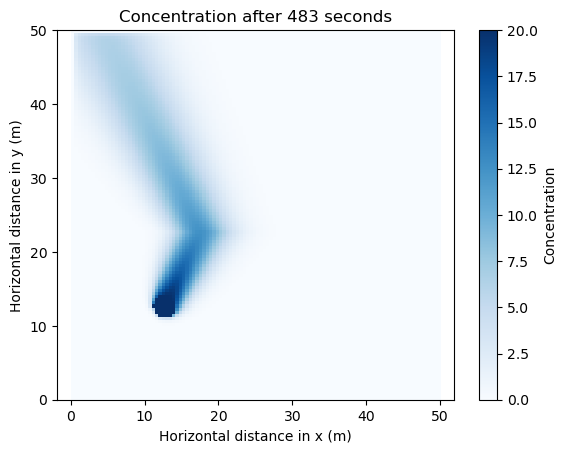

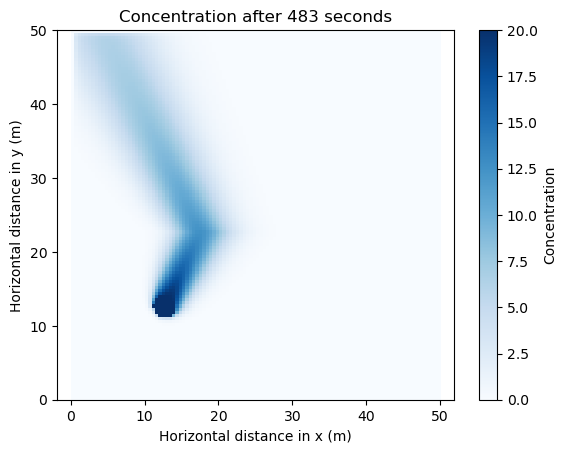

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# VERSION DU CODE à EFFECTUER
Q = 2

# PARAMèTRES PHYSIQUES
D = 0.02                    # diffusivité en m2/s
gamma = 0.001               # constante de décroissance
Cmax = 20                   # concentration du polluant
Lx = 50                     # longeur du domaine en m
Ly = 50                     # largeur du domaine en m
xfuite = Lx/4               # position de la fuite en x en m
yfuite = Ly/4               # position de la fuite en y en m
rc = 1.5                    # rayon de la fuite en m
vx = 0.1                    # vitesse x du lax en m/s (attention mettre un signe - pour le haut de Q=2)
vy = 0.2                    # vitesse y du lax en m/s

# PARAMèTRES NUMéRIQUES
nx = 110                    # nombre de cellules en x
ny = 120                    # nombre de cellules en y
ttot = 500                  # temps total en s
dx = Lx / (nx - 1)          # taille d'une cellule
dy = Ly / (ny - 1)
nout = 1000                 # afficher la figure chaque 100e step

# INITIALISATION  
time = 0  
x = np.linspace(0,Lx,nx)  
y = np.linspace(0,Ly,ny)    
X, Y = np.meshgrid(x, y)
Vx = np.ones((ny, nx-1)) * vx
Vy = np.ones((ny-1, nx)) * vy

if Q == 2:
    Vx[int(nx/2):, :] = -vx

dt = min(min(dx, dy)**2/(4.1*D), 0.01*(min(dx/np.max(np.abs(Vx)), dy/np.max(np.abs(Vy)))))
nt = int(ttot / dt) # nombre de pas de temps

fuite = np.sqrt((X-xfuite)**2 + (Y-yfuite)**2)  # position de la fuite
C = np.zeros((ny, nx))
# print(fuite)
# exit()
C[fuite<=rc]= Cmax

# DÉFINITION DU PLOT À L'EXTÉRIEUR DE LA BOUCLE
fig, ax = plt.subplots() 
s = ax.imshow(C, extent=[0, Lx, 0, Ly], origin='lower', cmap='Blues', vmin=0, vmax=Cmax) 
cbar = plt.colorbar(s, label='Concentration') 
#cbar.set_label("Temperature (°C)", rotation=270) 

# boucle temporelle
for it in range(1,nt):
    time += dt
    # mise à jour du flux de diffusion
    qx = -D * (C[:,1:] - C[:,:-1]) / dx         
    qy = -D * (C[1:,:] - C[:-1,:]) / dy
    dqxdx = -(qx[:,1:] - qx[:,:-1]) / dx        
    dqydy = -(qy[1:,:] - qy[:-1,:]) / dy 
    C[1:-1, 1:-1] += ( dqxdx[1:-1,:] + dqydy[:,1:-1] ) * dt
    # mise à jour de l'advection
    dCdta_xn = (Vx < 0) * -Vx * (C[:,1:] - C[:,:-1]) / dx  # pour Vx négative
    C[:,:-1] += dt * dCdta_xn                              
    dCdta_xp = (Vx > 0) * -Vx * (C[:,1:] - C[:,:-1]) / dx  # pour Vx positive
    C[:,1:]  += dt * dCdta_xp                              
    dAdy_a  = - Vy * (C[1:,:] - C[:-1,:]) / dy 
    C[1:,:]  += dAdy_a * dt                                # pour Vy positive
    # mise à jour de la réaction
    dCdt_r = - gamma * C
    C += dt*dCdt_r
    # mantien de la fuite dans le temps
    C[fuite<=rc]= Cmax
    # conditions de bord
    C[0, :]  = 0    # 1er ligne
    C[-1, :] = 0    # derniere ligne
    C[:, 0]  = 0    # 1er colonne
    C[:, -1] = 0    # derniere colonne
     
    if it % nout == 0:
        clear_output(wait=True)
        ax.cla() 
        ax.imshow(C, extent=[0, Lx, 0, Ly], origin='lower', cmap='Blues', vmin=0, vmax=Cmax)
        plt.gca().set_aspect("auto")
        plt.axis('equal')
        ax.set_title(f'Concentration after ' + str(int(time)) + ' seconds')
        ax.set_xlabel('Horizontal distance in x (m)')
        ax.set_ylabel('Horizontal distance in y (m)')
        #cbar.set_label("Temperature (°C)", rotation=270) 
    
        display(fig)